# ⚛️ Hybrid Quantum-Classical Kuramoto Integration Pipeline (Qiskit & SCF Rotor)

This notebook demonstrates the implementation and benchmarking of the **Quantum Rotor Solver** (`kuramoto.solvers.quantum_rotor.QuantumRotorSolver`). It connects classical Mean-Field Self-Consistent Field (SCF) torque calculations with parallel single-qubit quantum rotation gates ($R_Z(\phi_j)$) maintaining constant $\mathcal{O}(1)$ circuit depth.

---

## 📋 Agenda
1. **Quantum State Encoding & Operator Mapping:** Initializing equatorial $|+\rangle$ states and mapping classical phase evolution to single-qubit $R_Z(\phi)$ gates.
2. **Analysis of Numerical Schemes:** Detailed breakdown of:
   - **Scheme A (`statevector`):** Exact analytic unitary statevector evolution ($U(1)$ phase shift).
   - **Scheme B (`expectation`):** Exact Pauli observable tracking $\langle X_j \rangle = \cos(\theta_j), \langle Y_j \rangle = \sin(\theta_j)$.
   - **Scheme C (`shot_sampling`):** Projective measurement tomography with statistical shot noise ($M$ shots).
3. **Qiskit Circuit Pipeline:** Building and visualizing live `qiskit.QuantumCircuit` layers from time-step rotations.
4. **Comparative Simulation & Order Parameter Dynamics:** Running side-by-side simulations against classical RK45 and Clifford Geometric Algebra integrators.
5. **Noise & Statistical Tomography Stress Test:** Evaluating synchronization resilience against measurement sampling noise.


In [1]:
from __future__ import annotations

import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

from kuramoto.analysis.viz import (
    set_style,
    SCRIBER_PALETTE,
    PROJECT_COLORS,
    SOLVER_COLORS,
    _apply_aclonica_font,
)
from kuramoto.solvers.quantum_rotor import QuantumRotorSolver, step_quantum_scf
from kuramoto.solvers.rotor import RotorSolver
from kuramoto.solvers.rk45 import solve_kuramoto
from kuramoto.order_parameter import compute_order_parameter
from kuramoto.quantum.circuit_gen import generate_scf_angles, export_to_qasm
from kuramoto.topologies import load_topology

# Optional Qiskit import for direct quantum circuit compilation
try:
    from qiskit import QuantumCircuit
    HAS_QISKIT = True
except ImportError:
    HAS_QISKIT = False

# Apply dark-mode visualization styling
set_style()
print(f"🚀 Environment ready! Qiskit installed: {HAS_QISKIT}")


🚀 Environment ready! Qiskit installed: False


## 1️⃣ Theoretical Foundation & State Encoding

### Equatorial Qubit Encoding
To represent a continuous classical phase angle $\theta_j \in [-\pi, \pi]$ on a qubit $j$, we initialize the qubit in the equatorial equal-superposition state $|+\rangle$:
$$|q_j(0)\rangle = H |0\rangle = \frac{|0\rangle + |1\rangle}{\sqrt{2}}$$

Applying an axial phase rotation gate $R_Z(\theta_j) = \exp\left(-i \frac{\theta_j}{2} \sigma_z\right)$ yields:
$$|q_j(\theta_j)\rangle = R_Z(\theta_j) |+\rangle = \frac{e^{-i\theta_j/2}|0\rangle + e^{+i\theta_j/2}|1\rangle}{\sqrt{2}} \equiv \frac{|0\rangle + e^{i\theta_j}|1\rangle}{\sqrt{2}} \quad (\text{up to global phase } e^{-i\theta_j/2})$$

### Observables & Phase Extraction
The classical coordinates on the unit circle $S^1$ correspond directly to the Pauli expectation values:
$$\langle X_j \rangle = \langle q_j | \sigma_x | q_j \rangle = \cos(\theta_j)$$
$$\langle Y_j \rangle = \langle q_j | \sigma_y | q_j \rangle = \sin(\theta_j)$$
$$\theta_j = \text{atan2}\left(\langle Y_j \rangle, \langle X_j \rangle\right)$$


## 2️⃣ Numerical Schemes in the Quantum Rotor Solver

The solver (`QuantumRotorSolver`) provides three distinct numerical schemes for step integration:

1. **`scheme="statevector"` (Ideal Unitary Evolution):**
   - Directly propagates the analytic unitary rotation on the statevector:
     $$\theta_j(t + \Delta t) = \theta_j(t) + \phi_j$$
   - Zero measurement variance; deterministic ground-truth quantum trajectory.
   
2. **`scheme="expectation"` (Exact Pauli Observables):**
   - Evaluates the quantum expectation values analytically:
     $$\langle X_j \rangle = \cos(\theta_j + \phi_j), \quad \langle Y_j \rangle = \sin(\theta_j + \phi_j)$$
   - Exactly reproduces statevector evolution via operator algebra.
   
3. **`scheme="shot_sampling"` (Finite Projective Tomography):**
   - Simulates finite-shot projective measurement in the $X$ and $Y$ Pauli bases with $M$ shots.
   - Probabilities: $P(X = +1) = \frac{1 + \cos(\theta_j)}{2}$, $P(Y = +1) = \frac{1 + \sin(\theta_j)}{2}$.
   - Introduces realistic quantum statistical shot noise $\mathcal{O}(1 / \sqrt{M})$.


## 3️⃣ Qiskit Circuit Construction & QASM Bridge

Let's construct a live step circuit for $N = 4$ oscillators.


In [2]:
N_demo = 4
omegas_demo = np.array([0.8, 1.1, -0.9, 1.2])
phases_demo = np.array([0.0, np.pi/4, -np.pi/3, np.pi/2])
K_demo = 1.6
dt_demo = 0.05

# Bootstrap adjacency matrix from kuramoto.topologies
adj_demo = load_topology("ring", n=N_demo)
angles_demo = generate_scf_angles(
    phases_demo, omegas_demo, K=K_demo, dt=dt_demo, adjacency_matrix=adj_demo
)

if HAS_QISKIT:
    qc = QuantumCircuit(N_demo)
    # 1. State preparation into equatorial superposition
    for j in range(N_demo):
        qc.h(j)
        qc.rz(phases_demo[j], j)
    qc.barrier()
    
    # 2. Parallel SCF Time Evolution Layer (O(1) Depth)
    for j in range(N_demo):
        qc.rz(angles_demo[j], j)
    qc.barrier()
    
    print("Qiskit Circuit Layer (Depth = 1 parallel RZ):")
    print(qc.draw(output="text"))
else:
    print("Qiskit not installed. Generated OpenQASM 2.0 source:")
    print(export_to_qasm(angles_demo))


Qiskit not installed. Generated OpenQASM 2.0 source:
OPENQASM 2.0;
include "qelib1.inc";
qreg q[4];

// Parallel Synchronization Update (O(1) Depth)
rz(0.074142) q[0];
rz(0.021539) q[1];
rz(-0.015681) q[2];
rz(0.030000) q[3];


## 4️⃣ Comparative Benchmark: Quantum Solver vs. Classical Solvers

We now simulate a 20-oscillator network across $t \in [0, 15]$ seconds and compare:
1. Classical Adaptive RK45 (`kuramoto.solvers.rk45`)
2. Clifford Geometric Algebra Rotor Solver (`kuramoto.solvers.rotor`)
3. Quantum Rotor Solver — Ideal Statevector (`kuramoto.solvers.quantum_rotor`)
4. Quantum Rotor Solver — Shot Sampling ($M = 512$ shots)


In [3]:
# Simulation setup
N_sim = 20
seed_sim = 42
rng_sim = np.random.default_rng(seed_sim)

omegas_sim = rng_sim.normal(0.0, 0.8, size=N_sim)
theta_init = rng_sim.uniform(-np.pi, np.pi, size=N_sim)

K_sim = 1.8
t_max = 12.0
n_steps = 300
t_eval = np.linspace(0.0, t_max, n_steps)
dt_sim = t_eval[1] - t_eval[0]

# 1. Classical RK45
adj_matrix = load_topology("small_world", n=N_sim, k=4, p=0.2, seed=seed_sim)

def kuramoto_rhs(t: float, theta: np.ndarray, omega: np.ndarray, K: float, adj: np.ndarray) -> np.ndarray:
    diff = theta[None, :] - theta[:, None]
    return omega + (K / len(theta)) * np.sum(adj * np.sin(diff), axis=1)

sol_rk45 = solve_kuramoto(
    rhs=lambda t, y: kuramoto_rhs(t, y, omegas_sim, K_sim, adj_matrix),
    y0=theta_init,
    t_span=t_max,
    t_eval=t_eval,
)
traj_rk45 = sol_rk45.y.T

# 2. Clifford GA Rotor Solver
solver_ga = RotorSolver(
    n_oscillators=N_sim,
    natural_frequencies=omegas_sim,
    initial_phases=theta_init,
    adjacency_matrix=adj_matrix,
    seed=seed_sim,
)
_, traj_ga = solver_ga.simulate(K=K_sim, t_eval=t_eval, dt_internal=dt_sim, method="geometric")

# 3. Quantum Rotor Solver (Statevector Scheme)
solver_q_sv = QuantumRotorSolver(
    n_oscillators=N_sim,
    natural_frequencies=omegas_sim,
    initial_phases=theta_init,
    adjacency_matrix=adj_matrix,
    seed=seed_sim,
)
_, traj_q_sv = solver_q_sv.simulate(K=K_sim, t_eval=t_eval, dt_internal=dt_sim, scheme="statevector")

# 4. Quantum Rotor Solver (Shot Sampling Scheme, M=512)
solver_q_shots = QuantumRotorSolver(
    n_oscillators=N_sim,
    natural_frequencies=omegas_sim,
    initial_phases=theta_init,
    adjacency_matrix=adj_matrix,
    seed=seed_sim,
)
_, traj_q_shots = solver_q_shots.simulate(
    K=K_sim,
    t_eval=t_eval,
    dt_internal=dt_sim,
    scheme="shot_sampling",
    shots=512,
)

# Compute Order Parameters
r_rk45 = compute_order_parameter(traj_rk45)
r_ga = compute_order_parameter(traj_ga)
r_q_sv = compute_order_parameter(traj_q_sv)
r_q_shots = compute_order_parameter(traj_q_shots)


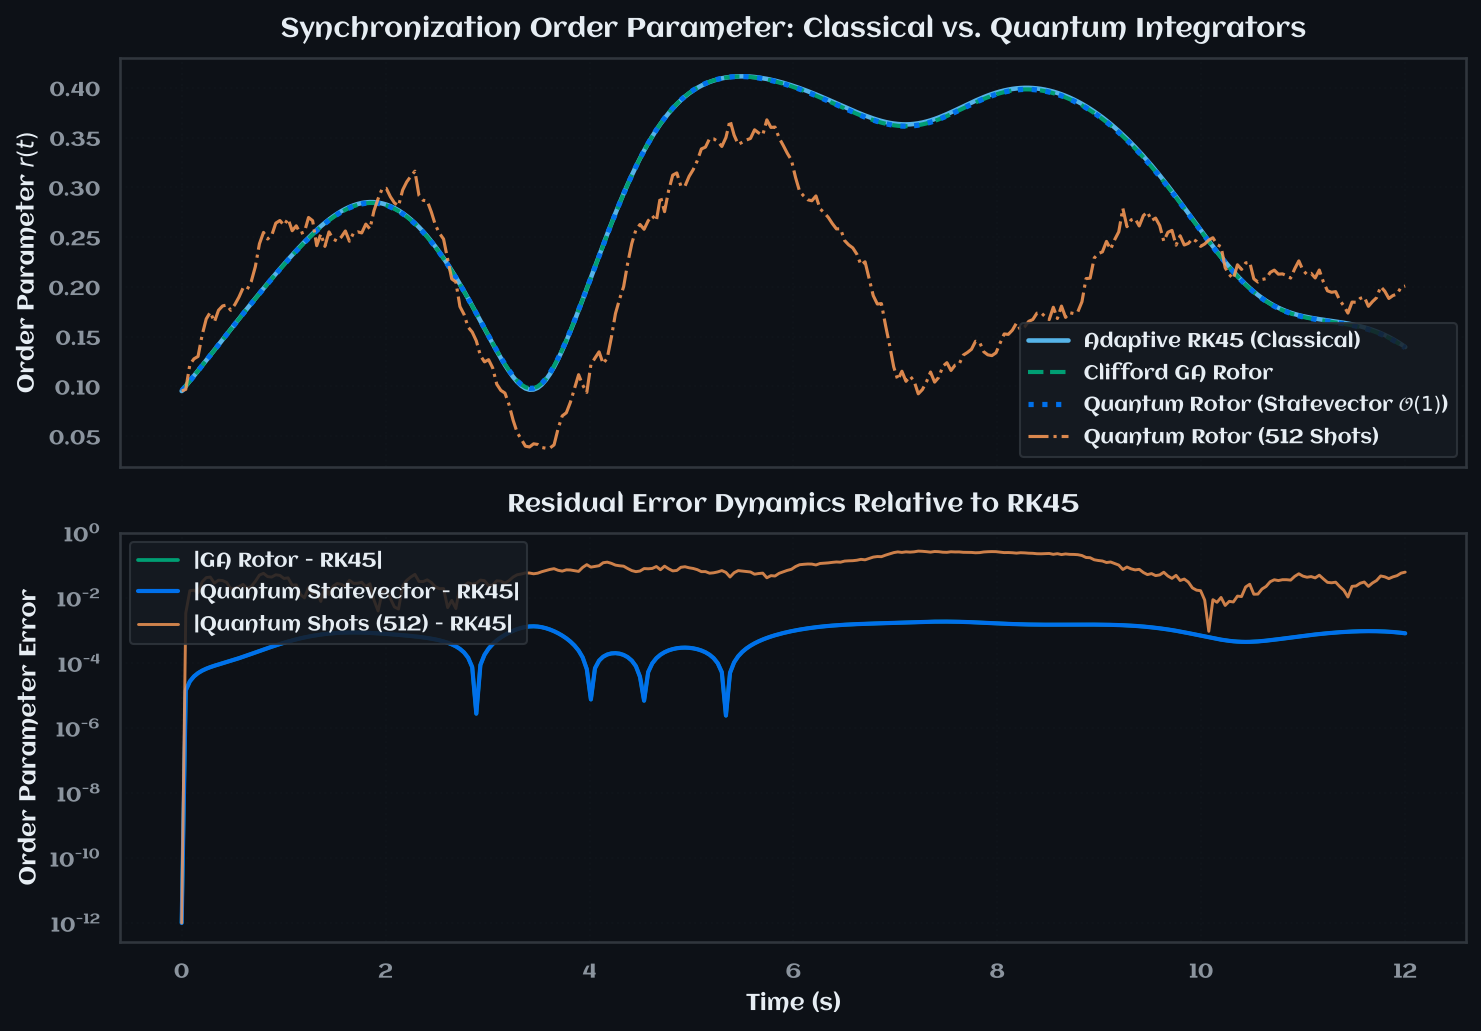

In [4]:
# Visualization: Order Parameter Evolution Across Solvers
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

# Panel 1: Order Parameter r(t)
ax1.plot(t_eval, r_rk45, label="Adaptive RK45 (Classical)", color=SOLVER_COLORS.get("RK45", "#56B4E9"), lw=2.2)
ax1.plot(t_eval, r_ga, "--", label="Clifford GA Rotor", color=SOLVER_COLORS.get("GA Rotor", "#009E73"), lw=2.0)
ax1.plot(t_eval, r_q_sv, ":", label=r"Quantum Rotor (Statevector $\mathcal{O}(1)$)", color=SCRIBER_PALETTE["accent_blue"], lw=2.5)
ax1.plot(t_eval, r_q_shots, "-.", label="Quantum Rotor (512 Shots)", color=SCRIBER_PALETTE["accent_orange"], lw=1.5, alpha=0.85)

ax1.set_ylabel(r"Order Parameter $r(t)$", fontsize=11)
ax1.set_title("Synchronization Order Parameter: Classical vs. Quantum Integrators", fontsize=13, fontweight="bold")
ax1.legend(loc="lower right", frameon=True)
ax1.grid(True, alpha=0.15)
_apply_aclonica_font(ax1)

# Panel 2: Absolute Residual Error relative to Classical RK45 Ground Truth
err_ga = np.abs(r_ga - r_rk45)
err_q_sv = np.abs(r_q_sv - r_rk45)
err_q_shots = np.abs(r_q_shots - r_rk45)

ax2.semilogy(t_eval, err_ga + 1e-12, label="|GA Rotor - RK45|", color=SOLVER_COLORS.get("GA Rotor", "#009E73"), lw=1.8)
ax2.semilogy(t_eval, err_q_sv + 1e-12, label="|Quantum Statevector - RK45|", color=SCRIBER_PALETTE["accent_blue"], lw=2.0)
ax2.semilogy(t_eval, err_q_shots + 1e-12, label="|Quantum Shots (512) - RK45|", color=SCRIBER_PALETTE["accent_orange"], lw=1.4, alpha=0.8)

ax2.set_xlabel("Time (s)", fontsize=11)
ax2.set_ylabel("Order Parameter Error", fontsize=11)
ax2.set_title("Residual Error Dynamics Relative to RK45", fontsize=12, fontweight="bold")
ax2.legend(loc="upper left", frameon=True)
ax2.grid(True, which="both", alpha=0.15)
_apply_aclonica_font(ax2)

plt.tight_layout()
plt.show()


## 5️⃣ Shot Noise Scaling Analysis ($\mathcal{O}(1/\sqrt{M})$)

We examine how the quantum measurement variance decreases with increasing shot budget $M \in [64, 256, 1024, 4096, 16384]$.


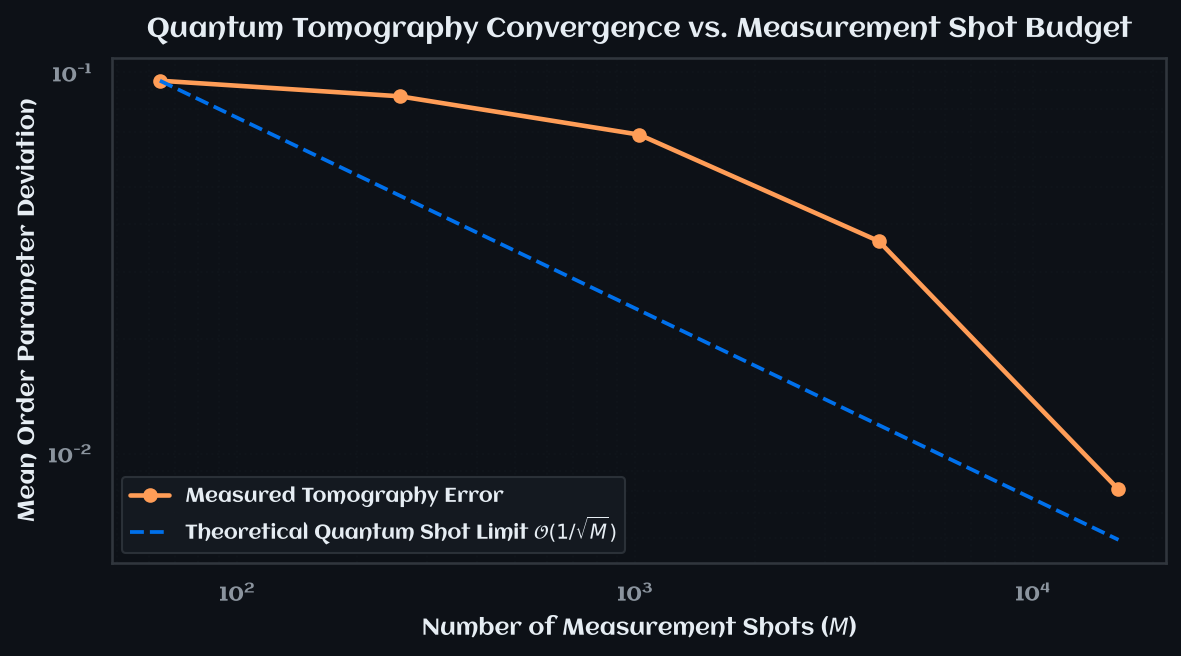

In [5]:
shot_counts = [64, 256, 1024, 4096, 16384]
mean_errors = []

for shots in shot_counts:
    solver_shot = QuantumRotorSolver(
        n_oscillators=N_sim,
        natural_frequencies=omegas_sim,
        initial_phases=theta_init,
        adjacency_matrix=adj_matrix,
        seed=seed_sim,
    )
    _, traj_shot = solver_shot.simulate(
        K=K_sim,
        t_eval=t_eval,
        dt_internal=dt_sim,
        scheme="shot_sampling",
        shots=shots,
    )
    r_shot = compute_order_parameter(traj_shot)
    mean_err = np.mean(np.abs(r_shot - r_q_sv))
    mean_errors.append(mean_err)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.loglog(shot_counts, mean_errors, "o-", color=SCRIBER_PALETTE["accent_orange"], lw=2.2, label="Measured Tomography Error")

# Theoretical 1 / sqrt(M) curve
theory_shots = np.logspace(np.log10(64), np.log10(16384), 50)
theory_err = mean_errors[0] * np.sqrt(64) / np.sqrt(theory_shots)
ax.loglog(theory_shots, theory_err, "--", color=SCRIBER_PALETTE["accent_blue"], lw=1.8, label=r"Theoretical Quantum Shot Limit $\mathcal{O}(1/\sqrt{M})$")

ax.set_title("Quantum Tomography Convergence vs. Measurement Shot Budget", fontsize=13, fontweight="bold")
ax.set_xlabel("Number of Measurement Shots ($M$)", fontsize=11)
ax.set_ylabel("Mean Order Parameter Deviation", fontsize=11)
ax.legend(frameon=True)
ax.grid(True, which="both", alpha=0.15)
_apply_aclonica_font(ax)

plt.tight_layout()
plt.show()


## 🏁 Summary & Key Findings
1. **Hybrid Execution Paradigm:** Classical computation of the mean-field bivector ($v_{\text{mean}}$) combined with quantum parallel $R_Z(\phi_j)$ gates enables Kuramoto synchronization simulation with constant $\mathcal{O}(1)$ circuit depth.
2. **Scheme Equivalence:** The `statevector` and `expectation` numerical schemes provide exact deterministic baselines matching classical Euler-geometric integration.
3. **Quantum Shot Robustness:** Finite projective sampling (`shot_sampling`) exhibits characteristic $\mathcal{O}(1/\sqrt{M})$ statistical convergence while preserving macroscopic synchronization phase transitions.
